In [6]:
import cv2
import matplotlib.pyplot as plt
import albumentations as A

In [13]:
def load_image(name):
  image = cv2.imread(name)
  image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
  return image

In [8]:
def display_image(image):
  plt.imshow(image)
  plt.show()

In [5]:
def process_image(image):
  image_resized = cv2.resize(image, (450, 800))
  image_rotated = cv2.rotate(image, cv2.ROTATE_180)
  image_flipped = cv2.flip(image, 1)
  gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
  return image_resized, image_rotated, image_flipped, gray_image

In [16]:
def augment_image(image):
  transform_1 = A.Compose([A.RandomCrop(height=100, width=100)])
  transform_2 = A.Compose([A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5)])
  transform_3 = A.Compose([A.GaussNoise()])
  transform_4 = A.Compose([A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=45, p=0.5), A.GridDistortion(p=0.5)])
  transform = A.Compose([A.RandomCrop(height=100, width=100),
                         A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
                         A.GaussNoise(),
                         A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=45, p=0.5),
                         A.GridDistortion(p=0.5)])
  image_1 = transform_1(image=image)['image']
  image_2 = transform_2(image=image)['image']
  image_3 = transform_3(image=image)['image']
  image_4 = transform_4(image=image)['image']
  final_image = transform(image=image)['image']
  return image_1, image_2, image_3, image_4, final_image

In [18]:
def display_all_images(original_image):
  img_res, img_rot, img_flip, img_gray = process_image(original_image)
  aug_1, aug_2, aug_3, aug_4, aug_final = augment_image(original_image)
  all_images = [
        ("Original", original_image),
        ("Resized (450x800)", img_res),
        ("Rotated 180", img_rot),
        ("Flipped", img_flip),
        ("Grayscale", img_gray),
        ("Random Crop", aug_1),
        ("Brightness/Contrast", aug_2),
        ("Gauss Noise", aug_3),
        ("Shift/Scale/Rot + Grid", aug_4),
        ("Combined Augmentations", aug_final)
    ]
  fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(10, 20))
  axes = axes.flatten()
  for ax, (title, img) in zip(axes, all_images):
        if len(img.shape) == 2:
            ax.imshow(img, cmap='gray')
        else:
            ax.imshow(img)

        ax.set_title(title, fontsize=14)
        ax.axis('off')

  plt.tight_layout()
  plt.show()

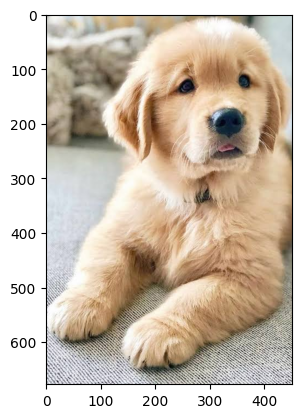

In [14]:
image_1 = load_image('image_dog.jpg')
display_image(image_1)

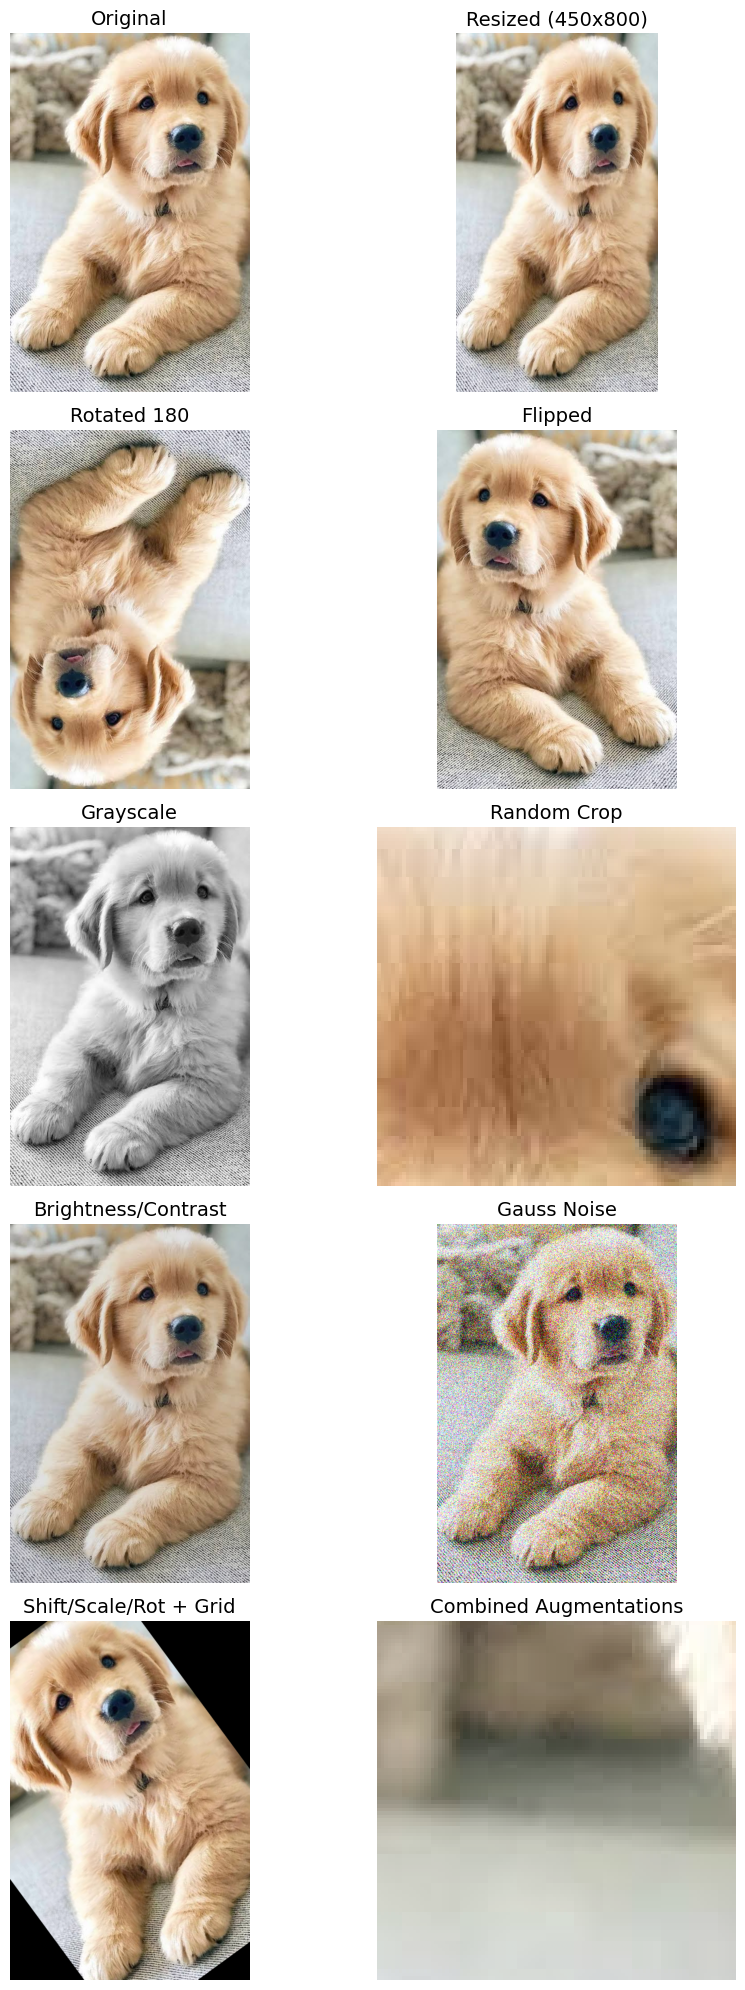

In [19]:
display_all_images(image_1)

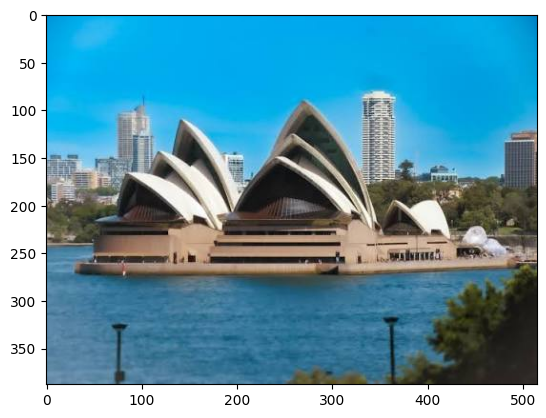

In [20]:
image_2 = load_image('image_theatre.jpg')
display_image(image_2)

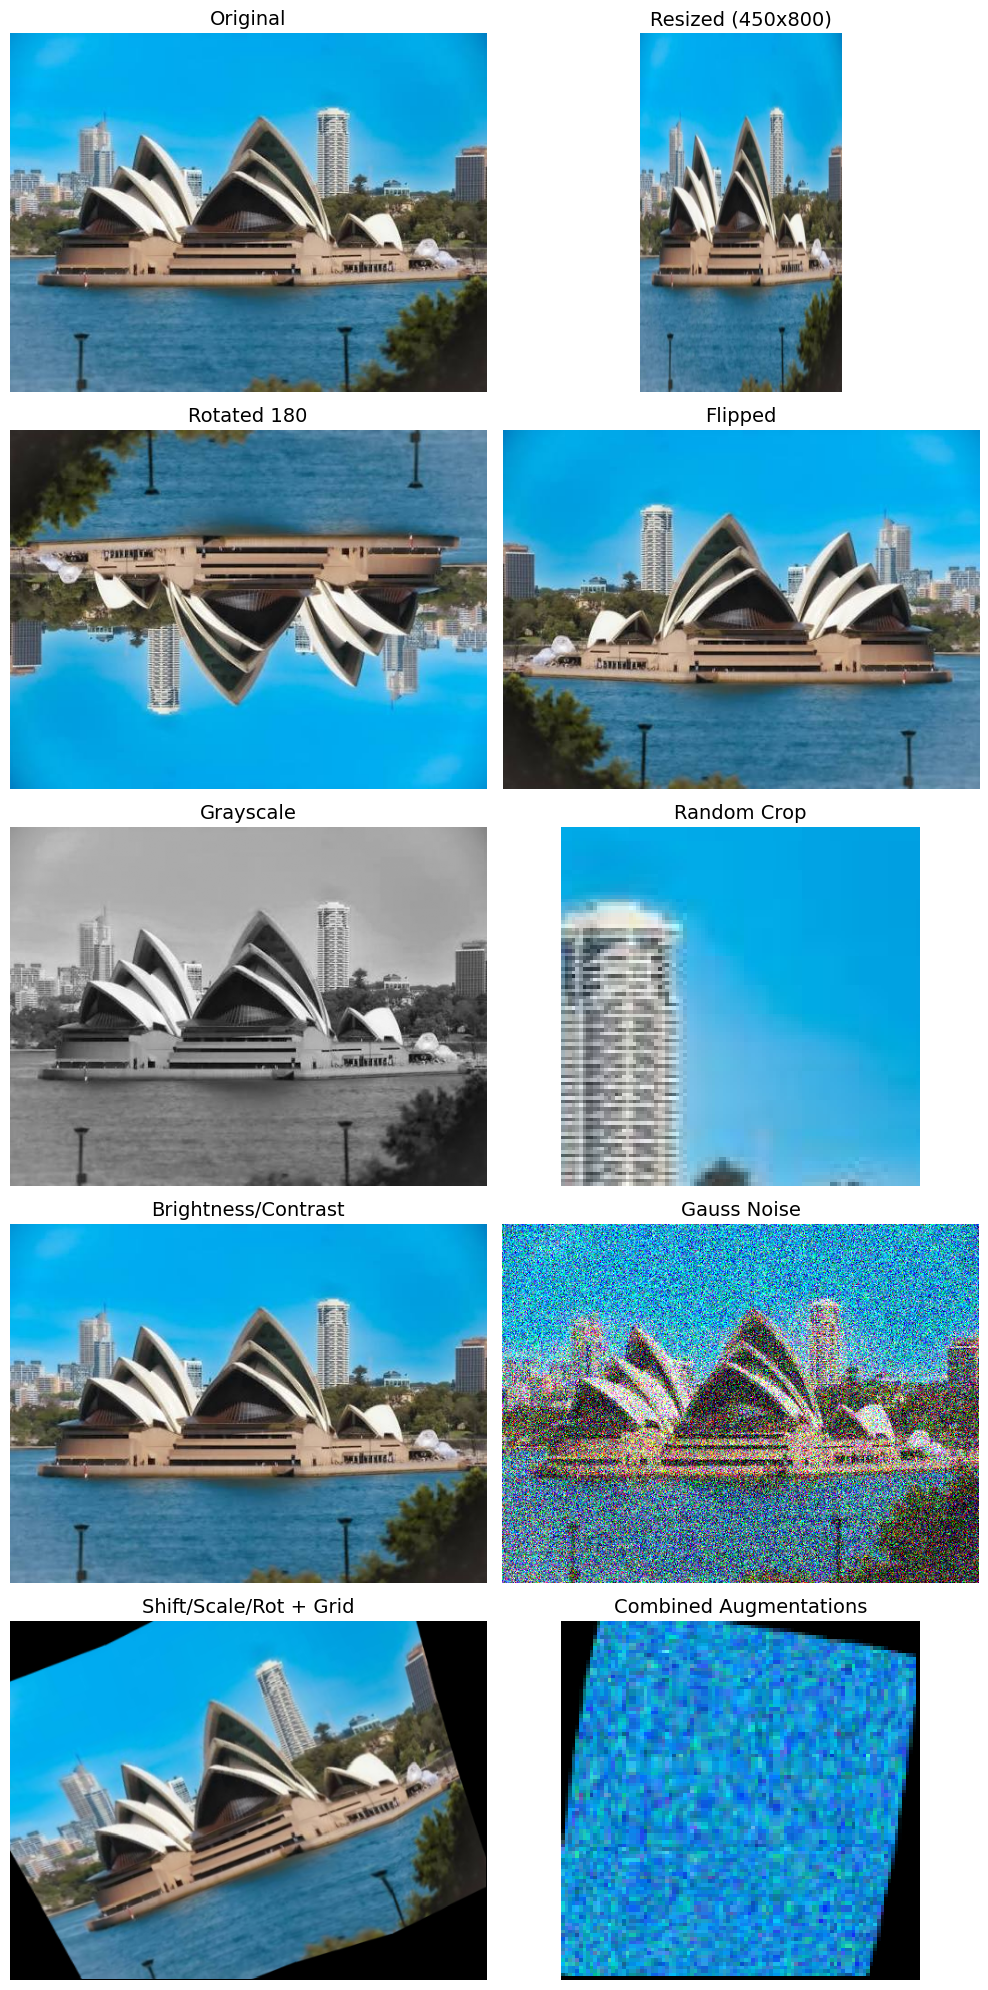

In [22]:
display_all_images(image_2)

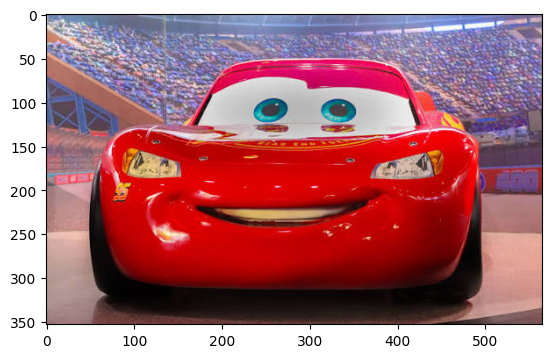

In [23]:
image_3 = load_image('image_car.jpg')
display_image(image_3)

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


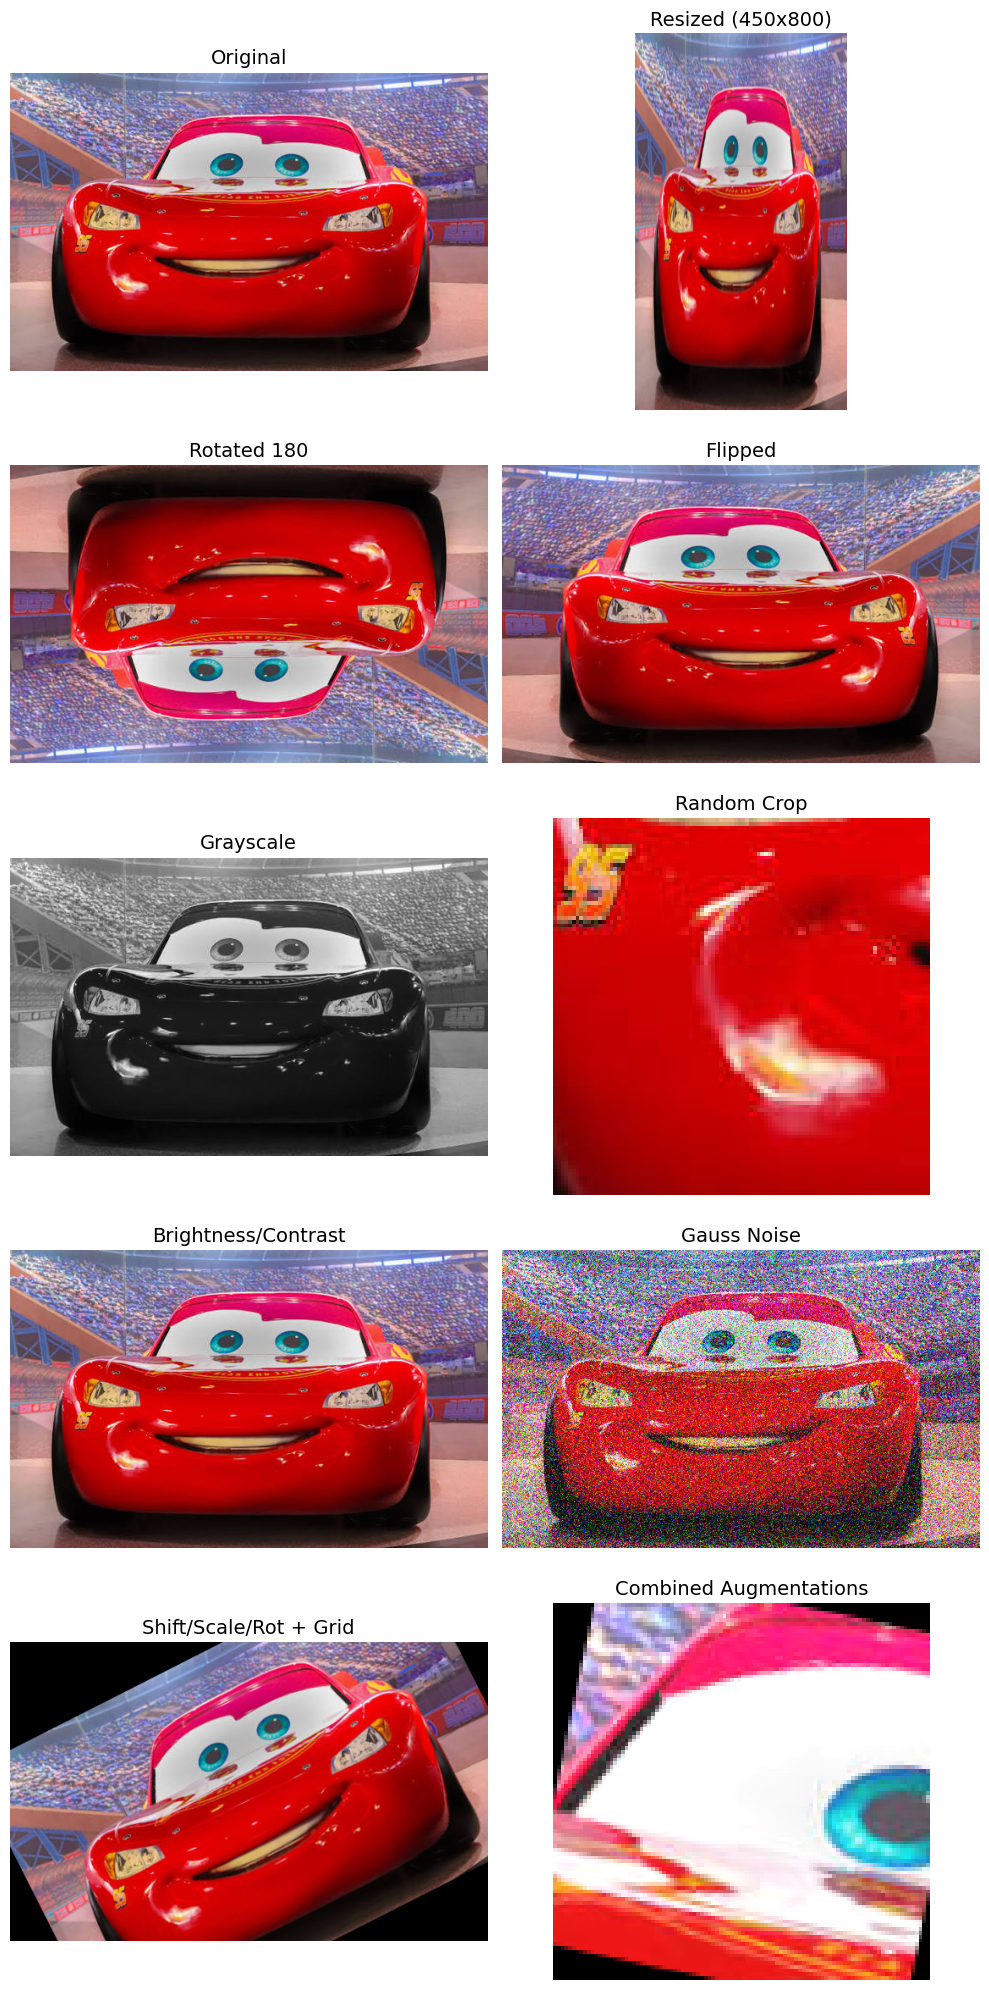

In [24]:
display_all_images(image_3)